<a href="https://colab.research.google.com/github/3b232100-yiren/2026_DL_hws/blob/main/hw3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#載入套件

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns

from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from sklearn.metrics import confusion_matrix
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

#a.資料預處理

In [14]:
# Fashion-MNIST 的 10 類別名稱 (對應 p.2-46 的標準標籤)
class_names = [
    'T-shirt/top (T恤/上衣)',
    'Trouser (褲子)',
    'Pullover (套頭衫)',
    'Dress (洋裝)',
    'Coat (外套)',
    'Sandal (涼鞋)',
    'Shirt (襯衫)',
    'Sneaker (運動鞋)',
    'Bag (包包)',
    'Ankle boot (短靴)'
]

fashion_mnist = tf.keras.datasets.fashion_mnist
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

print("--- 資料形狀 ---")
print("訓練圖片形狀 (X_train_full):", X_train.shape)
print("訓練標籤形狀 (y_train_full):", y_train.shape)
print("測試圖片形狀 (X_test):", X_test.shape)
print("測試標籤形狀 (y_test):", y_test.shape)

--- 資料形狀 ---
訓練圖片形狀 (X_train_full): (60000, 28, 28)
訓練標籤形狀 (y_train_full): (60000,)
測試圖片形狀 (X_test): (10000, 28, 28)
測試標籤形狀 (y_test): (10000,)


/tmp/ipykernel_5481/36932284.py:19: UserWarning: Glyph 27161 (\N{CJK UNIFIED IDEOGRAPH-6A19}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_5481/36932284.py:19: UserWarning: Glyph 31844 (\N{CJK UNIFIED IDEOGRAPH-7C64}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_5481/36932284.py:19: UserWarning: Glyph 30701 (\N{CJK UNIFIED IDEOGRAPH-77ED}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_5481/36932284.py:19: UserWarning: Glyph 38772 (\N{CJK UNIFIED IDEOGRAPH-9774}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_5481/36932284.py:19: UserWarning: Glyph 24676 (\N{CJK UNIFIED IDEOGRAPH-6064}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_5481/36932284.py:19: UserWarning: Glyph 19978 (\N{CJK UNIFIED IDEOGRAPH-4E0A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_5481/36932284.py:19: UserWarning: Glyph 34915 (\N{CJK UNIFIED IDEOGRAPH-8863}) missing from

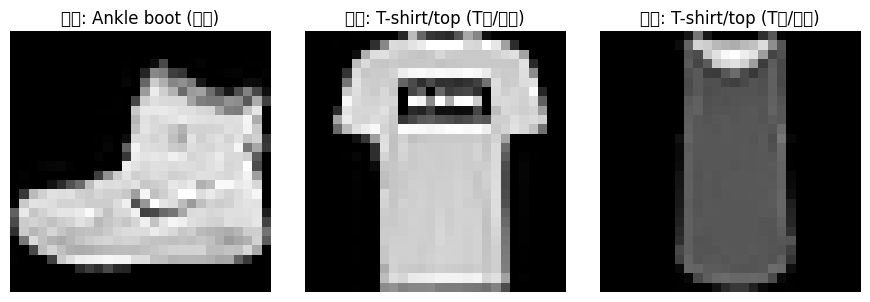

In [15]:
# 資料正規化
X_train_full = X_train / 255.0
X_test = X_test / 255.0

# 將標籤轉為 One-Hot Encoding 格式
y_train_full = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# 呈現至少三張訓練資料(圖片)及其真實的標籤(label)名稱
plt.figure(figsize=(9, 3))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(X_train_full[i], cmap='gray')
    label_idx = y_train_full[i]
    # 使用 np.argmax 將 One-Hot 編碼轉回整數索引
    class_idx = np.argmax(label_idx)
    plt.title(f"標籤: {class_names[class_idx]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

#b.建立神經網路模型

In [17]:
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(512, activation='relu'),
    Dropout(0.3),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
    ])

model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 535,818 (2.04 MB)

 Trainable params: 535,818 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

#c.訓練神經網路模型

In [19]:
model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

callbacks = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=7,
        mode="max",
        restore_best_weights=True,
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1,
    )
]

print("---  開始訓練模型 ---")
history = model.fit(
    X_train_full,
    y_train_full,
    batch_size=128,
    epochs=60,
    validation_split=0.2,
    callbacks=callbacks,
    verbose=1,
)

---  開始訓練模型 ---
Epoch 1/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - accuracy: 0.7903 - loss: 0.5837 - val_accuracy: 0.8537 - val_loss: 0.3971 - learning_rate: 0.0010
Epoch 2/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8465 - loss: 0.4198 - val_accuracy: 0.8553 - val_loss: 0.3974 - learning_rate: 0.0010
Epoch 3/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.8579 - loss: 0.3830 - val_accuracy: 0.8693 - val_loss: 0.3552 - learning_rate: 0.0010
Epoch 4/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8684 - loss: 0.3549 - val_accuracy: 0.8714 - val_loss: 0.3467 - learning_rate: 0.0010
Epoch 5/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.8744 - loss: 0.3422 - val_accuracy: 0.8704 - val_loss: 0.3450 - learning_rate: 0.0010
Epoch 6/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8786 - loss: 0.3260 - val_accuracy: 0.8791 - val_loss: 0.3279 - learning_rate: 0.0010
Epoch 7/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 

#d.Loss & Accuracy 折線圖

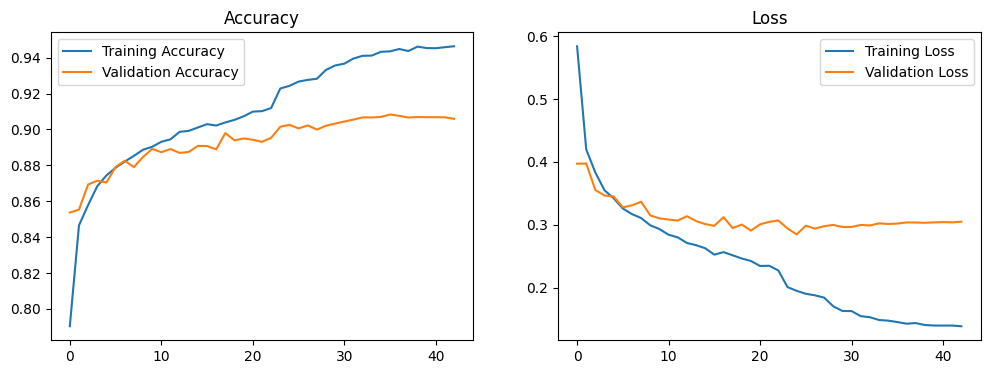

In [20]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss')
plt.legend()
plt.show()

#e.評估模型準確率

In [32]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)

print(f"測試資料 Loss：{test_loss:.4f}")
print(f"測試資料 Accuracy：{test_accuracy * 100:.2f}%")

if test_accuracy >= 0.90:
    print("已達到作業要求測試至少 90%準確率")
else:
    print("尚未達到90%，可調整後再重新訓練")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9018 - loss: 0.3308
測試資料 Loss：0.3308
測試資料 Accuracy：90.18%
已達到作業要求測試至少 90%準確率


#f.進行預測

In [38]:
y_pred_probs = model.predict(X_test, batch_size=128, verbose=1)

y_pred = np.argmax(y_pred_probs, axis=1)

print("預測機率陣列 shape：", y_pred_probs.shape)
print("預測標籤 shape：", y_pred.shape)

79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
預測機率陣列 shape： (10000, 10)
預測標籤 shape： (10000,)


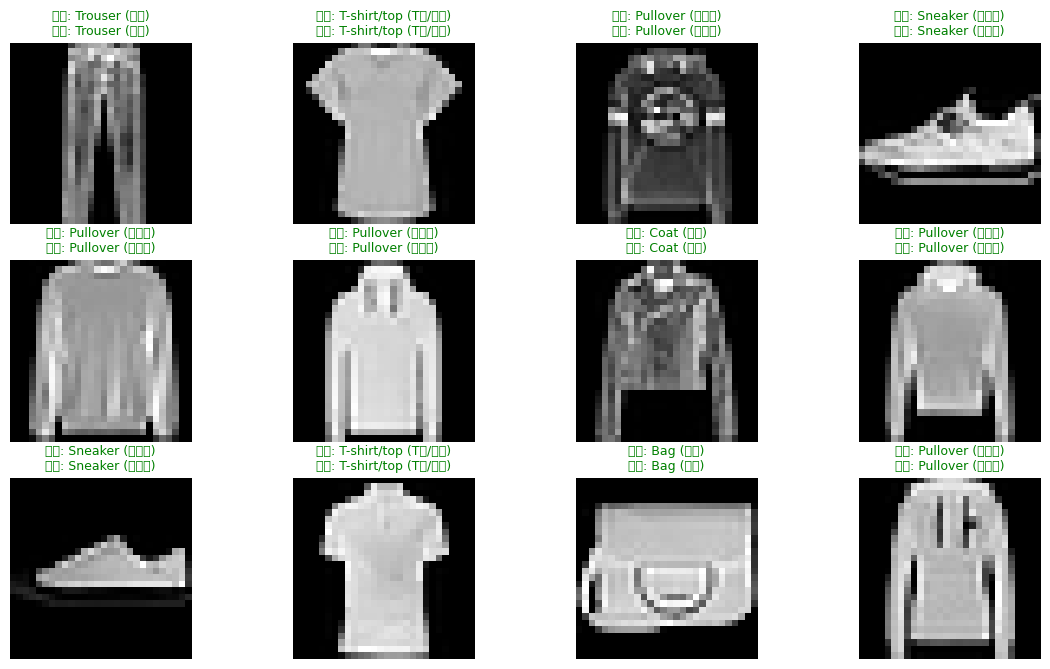

In [58]:
# 呈現測試圖片與真實標籤名稱
y_test_labels = np.argmax(y_test, axis=1)

random_indices = np.random.choice(len(X_test), 12, replace=False)
plt.figure(figsize=(14, 8))
for i, idx in enumerate(random_indices):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[idx], cmap='gray')
    true_label = class_names[y_test_labels[idx]]
    pred_label = class_names[y_pred[idx]]
    color = 'green' if y_pred[idx] == y_test_labels[idx] else 'red'
    plt.title(f"預測: {pred_label}\n真實: {true_label}", color=color, fontsize=9)
    plt.axis('off')
plt.show()

#g.混淆矩陣

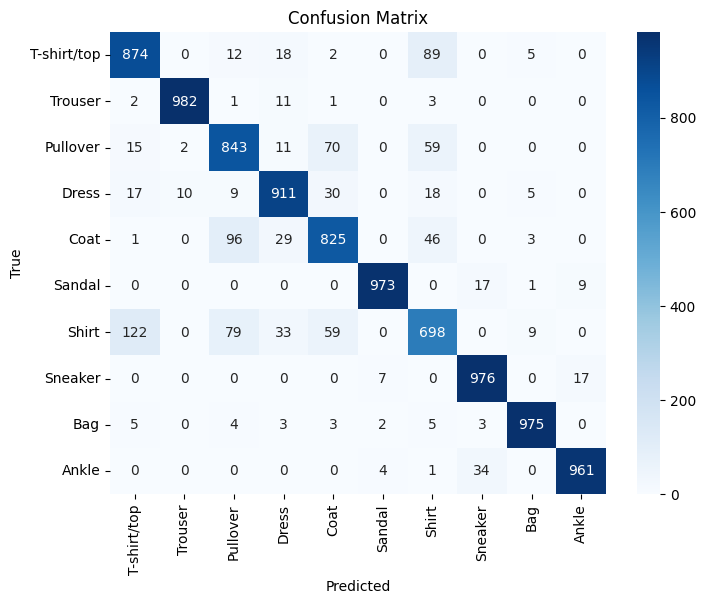

In [27]:
cm = confusion_matrix(y_test_labels, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[n.split()[0] for n in class_names],
            yticklabels=[n.split()[0] for n in class_names])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

#h.儲存完整模型

In [59]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [60]:
%cd '/content/drive/My Drive/Colab Notebooks'

/content/drive/My Drive/Colab Notebooks


In [61]:
model.save('my_dnn_model.keras')